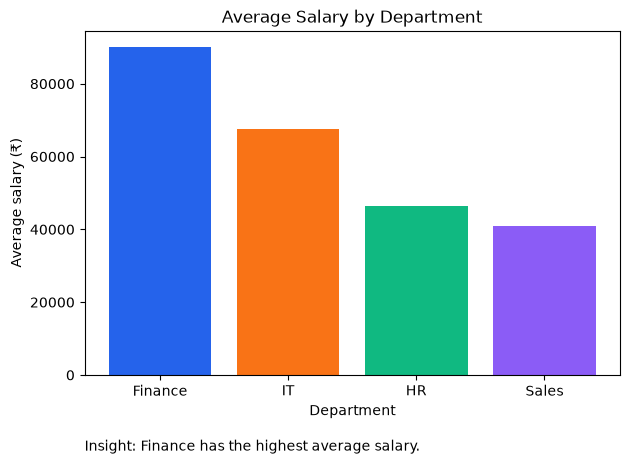

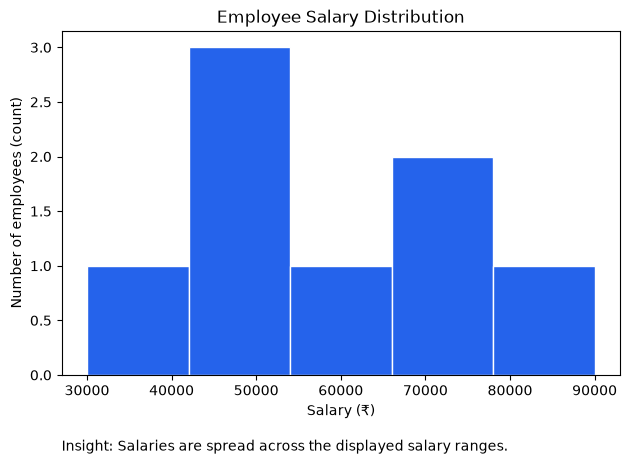

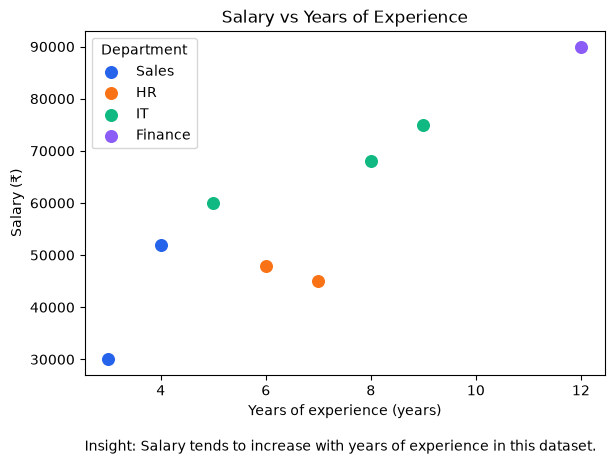

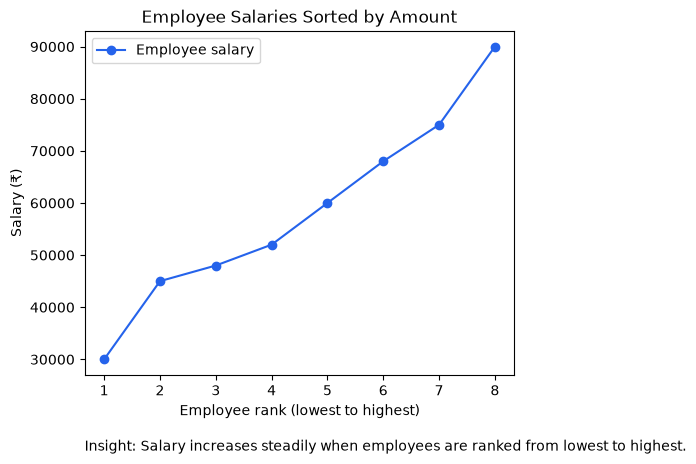

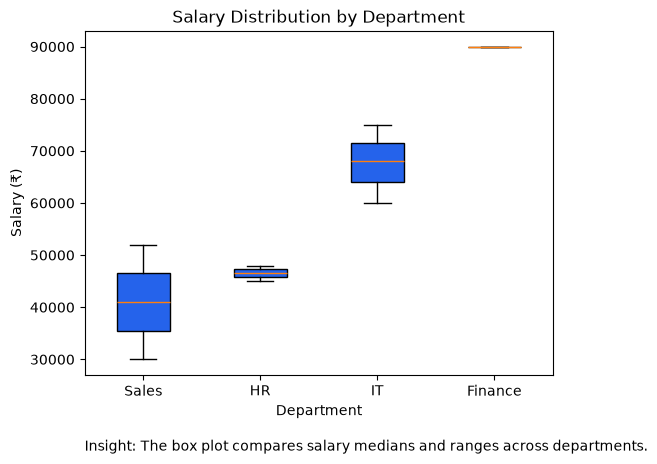

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("C:/Users/Lenovo/Desktop/Python/TASK/Day5_Task/Day5_SH_Task1/Emp_data.csv")

Path("reports/figures").mkdir(parents=True, exist_ok=True)

colors = ["#2563EB", "#F97316", "#10B981", "#8B5CF6"]


def save_chart(fig, filename):
    fig.tight_layout()
    fig.savefig(f"reports/figures/{filename}", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# 1. Bar chart: average salary by department
avg_salary = df.groupby("department")["salary"].mean().sort_values(ascending=False)
fig, ax = plt.subplots()
ax.bar(avg_salary.index, avg_salary.values, color=colors[:len(avg_salary)])
ax.set(title="Average Salary by Department",
       xlabel="Department", ylabel="Average salary (₹)")
ax.text(0, -0.22, f"Insight: {avg_salary.idxmax()} has the highest average salary.",
        transform=ax.transAxes)
save_chart(fig, "01_average_salary_by_department.png")


# 2. Histogram: salary distribution
fig, ax = plt.subplots()
ax.hist(df["salary"], bins=5, color=colors[0], edgecolor="white")
ax.set(title="Employee Salary Distribution",
       xlabel="Salary (₹)", ylabel="Number of employees (count)")
ax.text(0, -0.22, "Insight: Salaries are spread across the displayed salary ranges.",
        transform=ax.transAxes)
save_chart(fig, "02_salary_histogram.png")


# 3. Scatter plot: experience vs salary
fig, ax = plt.subplots()
for department, color in zip(df["department"].unique(), colors):
    part = df[df["department"] == department]
    ax.scatter(part["years_of_experience"], part["salary"],
               label=department, color=color, s=70)
ax.set(title="Salary vs Years of Experience",
       xlabel="Years of experience (years)", ylabel="Salary (₹)")
ax.legend(title="Department")
ax.text(0, -0.22, "Insight: Salary tends to increase with years of experience in this dataset.",
        transform=ax.transAxes)
save_chart(fig, "03_experience_vs_salary.png")


# 4. Line chart: salaries sorted from lowest to highest
sorted_salary = df.sort_values("salary").reset_index(drop=True)
fig, ax = plt.subplots()
ax.plot(range(1, len(sorted_salary) + 1), sorted_salary["salary"],
        marker="o", color=colors[0], label="Employee salary")
ax.set(title="Employee Salaries Sorted by Amount",
       xlabel="Employee rank (lowest to highest)", ylabel="Salary (₹)")
ax.legend()
ax.text(0, -0.22, "Insight: Salary increases steadily when employees are ranked from lowest to highest.",
        transform=ax.transAxes)
save_chart(fig, "04_sorted_salaries.png")


# 5. Box plot: salary by department
departments = df["department"].unique()
box_data = [df.loc[df["department"] == dept, "salary"] for dept in departments]
fig, ax = plt.subplots()
ax.boxplot(box_data, tick_labels=departments, patch_artist=True,
           boxprops={"facecolor": colors[0]})
ax.set(title="Salary Distribution by Department",
       xlabel="Department", ylabel="Salary (₹)")
ax.text(0, -0.22, "Insight: The box plot compares salary medians and ranges across departments.",
        transform=ax.transAxes)
save_chart(fig, "05_salary_boxplot_by_department.png")